### Gradient Descent
Gradient Descent is an **optimization algorithm** used to find model parameters that minimize a loss (cost) function. In linear regression, it helps the model learn the best values for the slope/coefficients and intercept.

#### Why do we use it?

- A model needs suitable parameter values to make accurate predictions.
- Gradient Descent improves those values by reducing the prediction error.
- It is useful when finding the best parameters directly is difficult or when working with large datasets.
- It is a common optimization method used in many machine learning algorithms.

#### How does it work?

1. **Initialize parameters :** Start with initial values for the coefficients and intercept.
2. **Make predictions :** Use the current parameters to calculate predicted values.
3. **Calculate the loss :** Measure the difference between actual and predicted values.
4. **Calculate gradients :** Find how the loss changes when each parameter changes.
5. **Update parameters :** Move the parameters in the opposite direction of the gradient.
6. **Repeat :** Continue for a number of iterations (epochs) until the loss becomes small or stops improving.

#### Update rule

For a parameter \(\theta\):

$$
\theta_{new} = \theta_{old} - \alpha \frac{\partial J}{\partial \theta}
$$

- \(\theta\): model parameter (such as a coefficient or intercept)
- \(\alpha\): learning rate, which controls the update step size
- \(J\): cost function
- Gradient: direction and rate of the cost's change


### What is Batch Gradient Descent?

In **Batch Gradient Descent**, the gradients are calculated using the **entire training dataset** before the parameters are updated. One complete pass through the dataset is used for each update.

This notebook demonstrates Gradient Descent for Simple Linear Regression, builds custom regression classes, visualizes parameter updates, and then applies Gradient Descent to Multiple Linear Regression.

In [1]:
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.datasets import make_regression
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score 
from sklearn.datasets import load_diabetes
from sklearn.model_selection import cross_val_score

### Simple Linear Regression

#### Gradient Descent with Simple Linear Regression

First, create a small synthetic dataset with one input feature and one target. The following examples focus on fitting a straight line to these points.

In [2]:
X,y = make_regression(n_samples=4, n_features=1, n_informative=1, n_targets=1, noise=80, random_state=13)

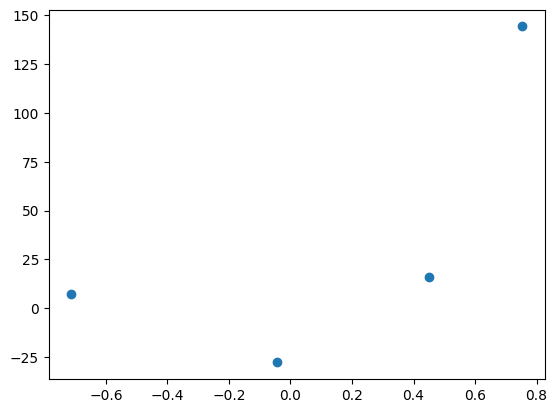

In [3]:
plt.scatter(X,y)

#### Compare with Ordinary Least Squares (OLS)

Train scikit-learn's `LinearRegression` model as a reference. OLS calculates the best-fit linear parameters directly by minimizing the sum of squared errors.

In [4]:
model = LinearRegression()

In [5]:
model.fit(X,y)

LinearRegression()

In [6]:
model.coef_   # slope 

array([78.35063668])

In [7]:
model.intercept_    # actual b 

np.float64(26.15963284313262)

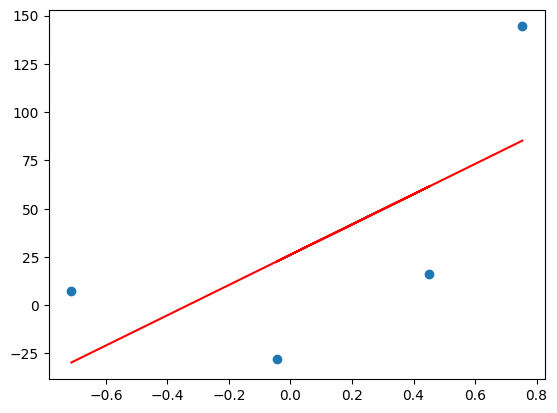

In [8]:
plt.scatter(X,y)
plt.plot(X, model.predict(X), color='red') 

#### Start Gradient Descent by updating the intercept

For this first manual demonstration, the slope (`m`) is kept fixed and only the intercept (`b`) is updated. We begin with an initial intercept value and calculate how far it should move to reduce the error.

In [9]:
# Lets apply Gradient Descent assumning slope is constant m = 78.35 
# assume random value of b = 0 

m = 78.35
b = 0

In [10]:
y_pred = (m*X+b).reshape(4)

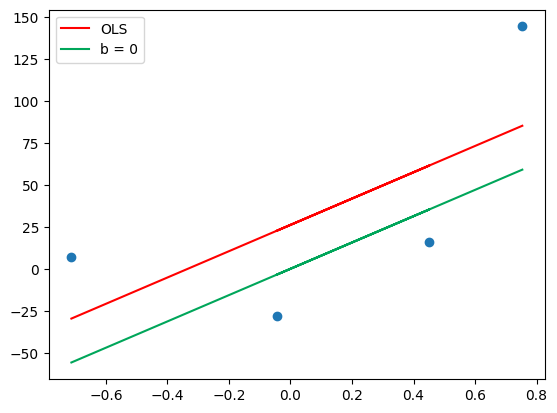

In [11]:
plt.scatter(X,y)
plt.plot(X, model.predict(X), color='red', label='OLS')
plt.plot(X, y_pred, color='#00a65a', label=f'b = {b}')

plt.legend()

In [12]:
# calculate slope 
# Iteration 1
loss_slope = -2 * np.sum(y - m*X.ravel() - b)
loss_slope

np.float64(-209.27763408209216)

In [13]:
# lets take Learning rate = 0.01
lr = 0.1

step_size = loss_slope*lr
step_size

np.float64(-20.927763408209216)

In [14]:
# Calculating the new intercept_
b1 = b - step_size
b1

np.float64(20.927763408209216)

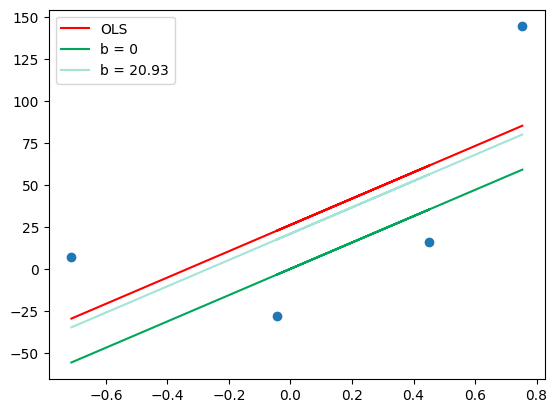

In [15]:
y_pred1 = (m*X+b1).reshape(4)

plt.scatter(X,y)
plt.plot(X, model.predict(X), color='red', label='OLS')
plt.plot(X, y_pred, color='#00a65a', label=f'b = {b}')
plt.plot(X, y_pred1, color='#a3e4d7', label=f'b = {round(b1,2)}')

plt.legend()

In [16]:
# Iteration 2
loss_slope = -2 * np.sum(y - m*X.ravel() - b1) 
step_size = loss_slope*lr
b2 = b1 - step_size
b2

np.float64(25.11331608985106)

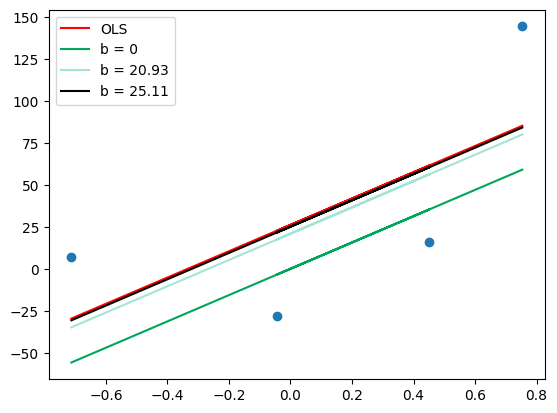

In [17]:
y_pred2 = (m*X+b2).reshape(4)

plt.scatter(X,y)
plt.plot(X, model.predict(X), color='red', label='OLS')
plt.plot(X, y_pred, color='#00a65a', label=f'b = {b}')
plt.plot(X, y_pred1, color='#a3e4d7', label=f'b = {round(b1,2)}')
plt.plot(X, y_pred2, color='#000', label=f'b = {round(b2,2)}')

plt.legend()

In [18]:
# Iteration 3
loss_slope = -2 * np.sum(y - m*X.ravel() - b2) 
step_size = loss_slope*lr
b3 = b2 - step_size
b3

np.float64(25.95042662617943)

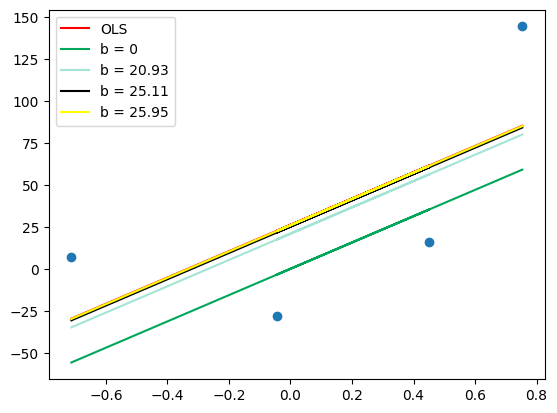

In [19]:
y_pred3 = (m*X+b3).reshape(4)

plt.scatter(X,y)
plt.plot(X, model.predict(X), color='red', label='OLS')
plt.plot(X, y_pred, color='#00a65a', label=f'b = {b}')
plt.plot(X, y_pred1, color='#a3e4d7', label=f'b = {round(b1,2)}')
plt.plot(X, y_pred2, color='#000', label=f'b = {round(b2,2)}')
plt.plot(X, y_pred3, color='yellow', label=f'b = {round(b3,2)}')

plt.legend()

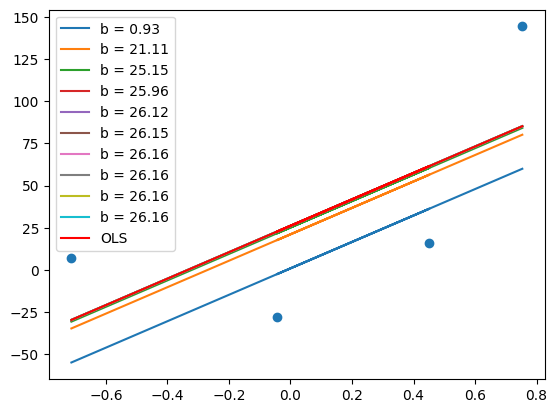

In [20]:
# Another Example 

b = -100
m = m
lr = 0.1

epochs = 10 

for i in range(epochs):
    loss_slope = -2 * np.sum(y - m*X.ravel() - b)
    b = b - (lr * loss_slope)

    y_pred = m * X + b

    plt.plot(X, y_pred, label=f'b = {round(b, 2)}')

plt.scatter(X,y)
plt.plot(X, model.predict(X), color='red', label='OLS')
plt.legend()
    

#### Repeat the update over multiple iterations

An **epoch** here means one complete update using all four training examples. The plots show how the line changes as the intercept is updated.

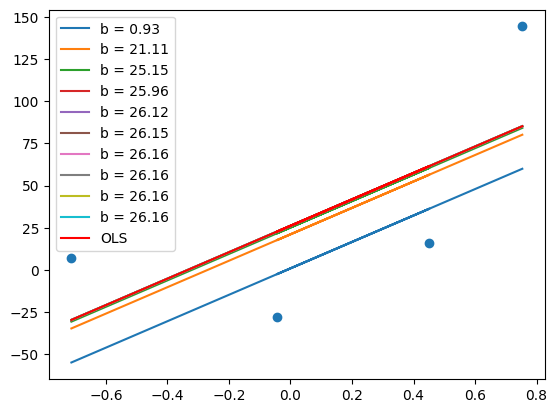

In [21]:
b = -100
m = m
lr = 0.1

epochs = 10

for i in range(epochs):
    loss_slope = -2 * np.sum(y - m*X.ravel() - b)
    b = b - (lr * loss_slope)

    y_pred = m * X + b

    plt.plot(X, y_pred, label=f'b = {round(b, 2)}')

plt.scatter(X,y)
plt.plot(X, model.predict(X), color='red', label='OLS')
plt.legend()

In [22]:
X,y = make_regression(n_samples=100, n_features=1, n_informative=1, n_targets=1, noise=20)

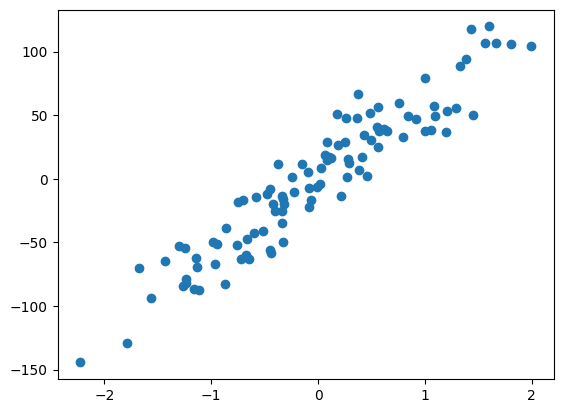

In [23]:
plt.scatter(X,y)

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=2)

In [25]:
model1 = LinearRegression()

In [26]:
model1.fit(X_train,y_train)

LinearRegression()

In [27]:
model1.intercept_   # b 

np.float64(0.7649132312665428)

In [28]:
model1.coef_ # m

array([58.63933183])

In [29]:
np.mean(cross_val_score(model1, X_test,y_test, scoring='r2', cv=10))

np.float64(-2.109912549728554)

In [30]:
y_pred = model1.predict(X_test)
r2_score(y_test, y_pred)

0.9100717442830965

In [31]:
# slope 
m = 91.484

#### Implement Simple Linear Regression with Gradient Descent

In [32]:
# main class implement Gradient Descent
class GDRegressor: 

    def __init__(self, learning_rate=0.01, epochs=100): 
        self.m = 100  
        self.b = -120
        self.lr = learning_rate
        self.epochs = epochs

    def fit(self, X,y): 

        # calculate b and b using GD 
        for i in range(self.epochs): 
            loss_slope_b = -2 * np.sum(y - self.m*X.ravel() - self.b)
            loss_slope_m = -2 * np.sum((y - self.m*X.ravel() - self.b)*X.ravel())
            self.b = self.b - (self.lr * loss_slope_b)
            self.m = self.m - (self.lr * loss_slope_m)

        print('Using GD b :',self.b)
        print('Using GD slope (m) :',self.m)

    def predict(self, x):
        return np.array(self.m * x + self.b)

#### Observe the effect of the learning rate and number of epochs

The next example uses a smaller learning rate and more epochs. The learning rate controls the size of each parameter update; too large a value can overshoot the minimum, while too small a value can make learning slow.

In [33]:
gd = GDRegressor(learning_rate=0.001, epochs=100)

In [34]:
print('USing OLS b : ', model1.intercept_)
print('USing OLS m : ', model1.coef_ , '\n')
gd.fit(X_train,y_train)

USing OLS b :  0.7649132312665428
USing OLS m :  [58.63933183] 

Using GD b : 0.7649163708430419
Using GD slope (m) : 58.63935484031684


In [35]:
y_pred_gd = gd.predict(X_test)
r2_score(y_test, y_pred_gd)

0.9100717882626318

#### Gradient Descent Animation 

This section records the parameter values after each epoch and uses Matplotlib animation to show how the regression line moves during training.

- `all_b` stores the intercept values after each epoch.
- `all_m` stores the slope values after each epoch.
- `all_cost` is initialized to store cost values; the loop calculates a cost for each epoch, although this list is not populated in the current code.

The animation is saved as `gd_animation.gif` in the notebook's working directory.

In [36]:
# %matplotlib notebook
from matplotlib.animation import FuncAnimation
import matplotlib.animation as animation

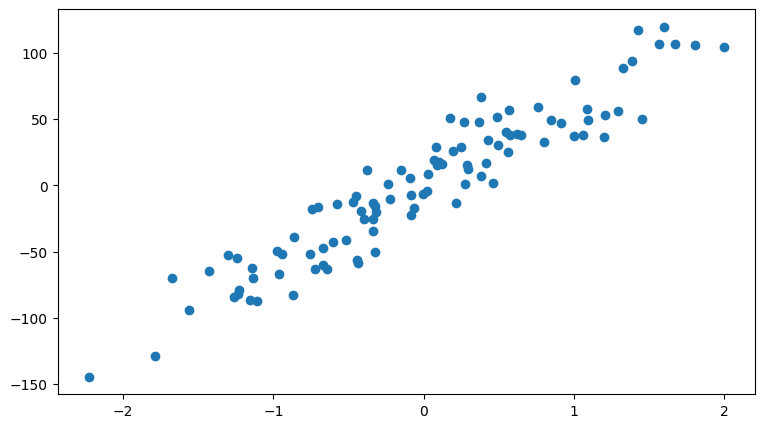

In [37]:
plt.figure(figsize=(9,5))
plt.scatter(X,y)

In [38]:
b = 100
m = -120
lr = 0.001
all_b = []
all_m = []
all_cost = [] 

epochs = 40 

for i in range(epochs):
    slope_b = 0
    slope_m = 0
    cost = 0

    for j in range(X.shape[0]): 
        slope_b = slope_b - 2*(y[j] - (m * X[j]) - b)
        slope_m = slope_m - 2*(y[j] - (m * X[j]) - b) * X[j]
        cost = cost + (y[j] - m * X[j] - b ) ** 2 

    b = b - (lr * slope_b)
    m = m - (lr * slope_m)
    all_b.append(b)
    all_m.append(m)


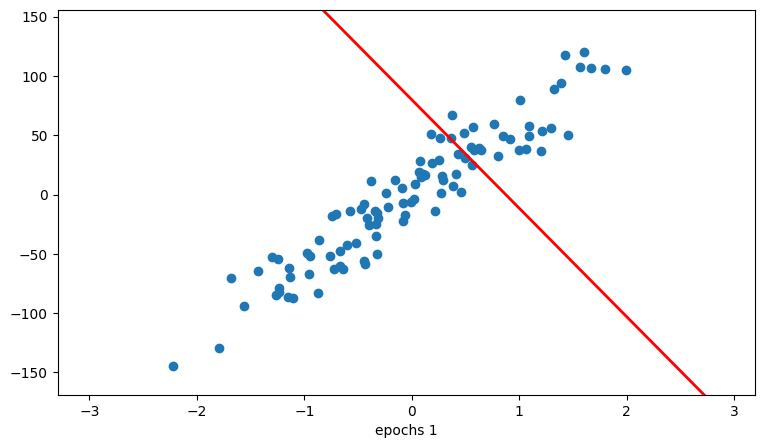

In [39]:
fig, ax = plt.subplots(figsize=(9,5))

x_i = np.arange(-3, 3, 0.1)
y_i = x_i *(-27) - 150

ax.scatter(X,y)
line, = ax.plot(x_i, x_i*50 - 4, 'r-', linewidth=2)

def update(i): 
    label = f'epochs {i+1}'
    line.set_ydata(x_i*all_m[i]+all_b[i])
    ax.set_xlabel(label)
   
anim = FuncAnimation(fig, update, repeat=True, frames=epochs, interval=500)

f = r"gd_animation.gif"
writergif = animation.PillowWriter(fps=2) 
anim.save(f, writer=writergif)

### Multiple Linear Regression
#### Gradient Descent with Multiple Linear Regression

So far, the examples used one input feature. Multiple Linear Regression uses two or more input features to predict a numerical target.

The model is:

$$
\hat{y} = b + w_1x_1 + w_2x_2 + \cdots + w_nx_n
$$

Here, each input feature has its own coefficient (weight), and the model also learns an intercept.

#### Load and prepare the Diabetes dataset

The scikit-learn Diabetes dataset contains multiple input features and a numerical target. Split it into training and testing sets so model performance can be evaluated on data not used for training.

In [40]:
X, y = load_diabetes(return_X_y=True)

In [41]:
print(X.shape)
print(y.shape)

(442, 10)
(442,)


#### Train a Multiple Linear Regression baseline

Fit scikit-learn's `LinearRegression` model and inspect its coefficients and intercept. This provides a baseline for comparison with the custom Gradient Descent implementation.

In [42]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=2)

In [43]:
reg = LinearRegression()

In [44]:
reg.fit(X_train, y_train)

LinearRegression()

In [45]:
print('coef_ :', reg.coef_, '\n')
print('intercept_ :', reg.intercept_)

coef_ : [  -9.15865318 -205.45432163  516.69374454  340.61999905 -895.5520019
  561.22067904  153.89310954  126.73139688  861.12700152   52.42112238] 

intercept_ : 151.88331005254167


#### Implement Multiple Linear Regression with Gradient Descent

Now implement Gradient Descent in a Python class. This version learns both the slope (`m`) and intercept (`b`) instead of keeping the slope fixed.

The `fit()` method repeatedly calculates the gradients for both parameters and updates them. The `predict()` method uses the learned parameters to make predictions.

The custom `multiGDRegressor` class learns:
- One intercept (`intercept_`).
- One coefficient for each input feature (`coef_`).

At each epoch, it predicts the target values, calculates the average gradients for the intercept and coefficients using the full training dataset, and updates all parameters. Using the full dataset for each update makes this **Batch Gradient Descent**.

In [46]:
class multiGDRegressor: 
    def __init__(self, learning_rate=0.01, epcohs=100): 
        self.coef_ = None
        self.intercept_ = None
        self.lr = learning_rate
        self.epcohs = epcohs

    def fit(self, X_train, y_train): 

        # set random coefs and intercept values
        self.intercept_ = 0 
        self.coef_ = np.ones(X_train.shape[1])

        for i in range(self.epcohs): 

            y_hat = np.dot(X_train, self.coef_) + self.intercept_
            
            # for intercept 
            slope_intercept = -2 * np.mean(y_train - y_hat)

            # for coefs 
            slope_coef = -2 * np.dot((y_train - y_hat), X_train) /  X_train.shape[0]
            
            # update coefs and intercept values
            self.intercept_ = self.intercept_ - (self.lr * slope_intercept)
            self.coef_ = self.coef_ - (self.lr * slope_coef)

        print('intercept_ :', self.intercept_)
        print('coefs_ :', self.coef_)

    def predict(self, X_test): 
        return np.dot(X_test, self.coef_) + self.intercept_
    

In [47]:
mgd = multiGDRegressor(learning_rate=0.1, epcohs=1700)

In [48]:
mgd.fit(X_train, y_train)

intercept_ : 152.0998464148823
coefs_ : [  57.14659109  -63.4886528   346.17633585  245.34653242   19.65499506
  -25.15767577 -171.63728559  130.38780311  315.30511074  129.48104162]


In [49]:
mgd.intercept_

np.float64(152.0998464148823)

In [50]:
y_pred = mgd.predict(X_test)

In [51]:
print('r2_score :', r2_score(y_test, y_pred))

r2_score : 0.4319231567622862


In [52]:
y_pred = reg.predict(X_test)
print('r2 score : ', r2_score(y_test, y_pred))

r2 score :  0.4399338661568968


### Key Takeaways

1. Gradient Descent is an optimization algorithm that minimizes a model's loss function.
2. It updates parameters in the opposite direction of the gradient.
3. The learning rate controls the size of each update.
4. An epoch is one complete pass through the training data for the update strategy being used.
5. Batch Gradient Descent calculates gradients using the full training dataset before each update.
6. For Simple Linear Regression, Gradient Descent can learn the slope and intercept.
7. For Multiple Linear Regression, it learns one coefficient per feature along with an intercept.
8. Always evaluate predictions on test data that was not used to train the model.

**Remember:** Gradient Descent is an optimization algorithm, not a regression model. It can be used to train different models by minimizing their loss functions.